# E3 — TabICLv2

Evaluación local del método elegido por el usuario. Los resultados se guardan separados de los modelos previos y del dashboard.

## TabICLv2 oficial: qué se ejecuta

Paquete `tabicl==2.2.0`, [implementación oficial](https://github.com/soda-inria/tabicl)
y [artículo ICML2026](https://proceedings.mlr.press/v306/qu26a.html). Checkpoint oficial
de regresión `tabicl-regressor-v2-20260212.ckpt`, revisión de HuggingFace
`4dcd344ece2c00be9e831fdd35bed57b5ad83e19`, SHA256
`0db9cb538f114e79026bf08f45f41ad8dd7ad2de2aaca9a5ca8cd3bd9748ae7a`.

Inferencia local en contexto, **sin fine-tuning**: ocho estimadores, CPU cuatro hilos,
batch de ensamble1, semilla42. Preparación externa idéntica a SVM/TabPFN original.
Configuración fijada antes de evaluar: `norm_methods=['none']` evita transformaciones
de potencia/cuantiles y ruido RTDL; `outlier_threshold=infinity` desactiva el tratamiento
de outliers. La normalización numérica interna del modelo sigue activa. Se conservan
todas las filas; no se submuestrean estudiantes. Esta configuración controlada no
reproduce exactamente todos los defaults ni los benchmarks del artículo.

Cinco folds externos idénticos; **no hay selección interna**, porque no se ajustan
hiperparámetros. Cada contexto contiene solo fit. Los pesos quedan fijos y locales.
Los modelos serializados conservan el contexto y una referencia al checkpoint, evitando
duplicar114MB de pesos por fold. No requieren enviar datos a APIs.

## Datos y protocolo compartido

Misma fuente real y reglas de negocio de entregable3.py; sin aumentación, mismos15
predictores y objetivo nota_primer_parcial. ID, periodo, fila fuente y nota_final
excluidos como entradas. Train1309 filas/1293 estudiantes, test202530 con188 filas/
188 estudiantes, sin personas compartidas. Los cinco folds externos se verifican
contra los archivos canónicos. Todo preprocesador se aprende exclusivamente en fit.

La configuración final se guarda antes de predecir test. RMSE, MAE, MAPE(%) y R²
se calculan con la función del tablero en escala original, sin recortar predicciones.
Se separan media/SD de folds(ddof0), OOF reunido y test temporal. MAPE es sensible
a notas próximas a cero. Las métricas de CV no se mezclan con las de test.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display
BOOK=Path.cwd() if (Path.cwd()/'entregable3.py').exists() else Path.cwd()/'Precalculo'
sys.path.insert(0,str(BOOK.resolve()))
from comparacion_seleccionados_e3 import run,candidate_grid
key='tabicl_v2'
display(pd.DataFrame(candidate_grid(key)))
report=run(key,force=False)
display(pd.DataFrame(report['cv']).round(6))
display(pd.DataFrame(report['fold_audit']))
print('Parámetros finales:',report['best_params'])
print('Base XGBoost:',report['xgboost_base_params'])

""
0


tabicl_v2: resultado completo verificado.


,metrica,media_cv,sd_cv,OOF_agrupado
0,RMSE,0.807163,0.041293,0.808217
1,MAE,0.637544,0.037935,0.637546
2,MAPE (%),24.029936,2.055625,24.029501
3,R²,0.474892,0.056218,0.477025


,fold,fit_rows,validation_rows,shared_students,best_params,xgboost_base_params,inner_rmse,seconds
0,1,1047,262,0,{},None,None,39.376177
1,2,1047,262,0,{},None,None,34.347601
2,3,1047,262,0,{},None,None,34.680161
3,4,1047,262,0,{},None,None,34.502000
4,5,1048,261,0,{},None,None,34.929217


Parámetros finales: {}
Base XGBoost: None


## Comparación con las referencias anteriores

Cada panel tiene su propia métrica y escala. Naranja identifica este método;
verde, TabPFN original. La tabla incluye las etapas nuevas completadas hasta este
método, respetando el orden TCR → TabICL → HRT. Los modelos activos del dashboard
y los notebooks históricos se conservan.

,Modelo,RMSE,MAE,MAPE (%),R²
12,TabICLv2,0.897815,0.717104,28.412106,0.464774
8,TabPFN 2.5 original,0.898277,0.715491,27.761050,0.464223
9,TabPFN 2.5 fine-tuned,0.901370,0.722380,28.072635,0.460527
6,XGBoost,0.906274,0.728918,28.404775,0.454641
11,TCR-XGBoost,0.907695,0.737890,28.571924,0.452929
3,Ridge,0.917090,0.754511,29.572140,0.441545
4,Lasso,0.919650,0.753040,29.551967,0.438424
2,KNN,0.923270,0.754027,29.584495,0.433995
7,logicDT propio (adaptado),0.926438,0.760954,29.658839,0.430104
0,SVM lineal,0.927706,0.755443,29.664556,0.428543


,referencia,metrica,diferencia_ajustado_menos_referencia,IC_2.5%,IC_97.5%,p_bilateral,p_Holm_dos_pares
0,SVM lineal,RMSE,-0.029891,-0.057445,-0.004322,0.02624,0.05248
1,SVM lineal,R²,0.036232,0.005260,0.072372,0.02624,0.05248
2,TabPFN original,RMSE,-0.000463,-0.019632,0.018058,0.96184,0.96184
3,TabPFN original,R²,0.000552,-0.020527,0.025459,0.96184,0.96184


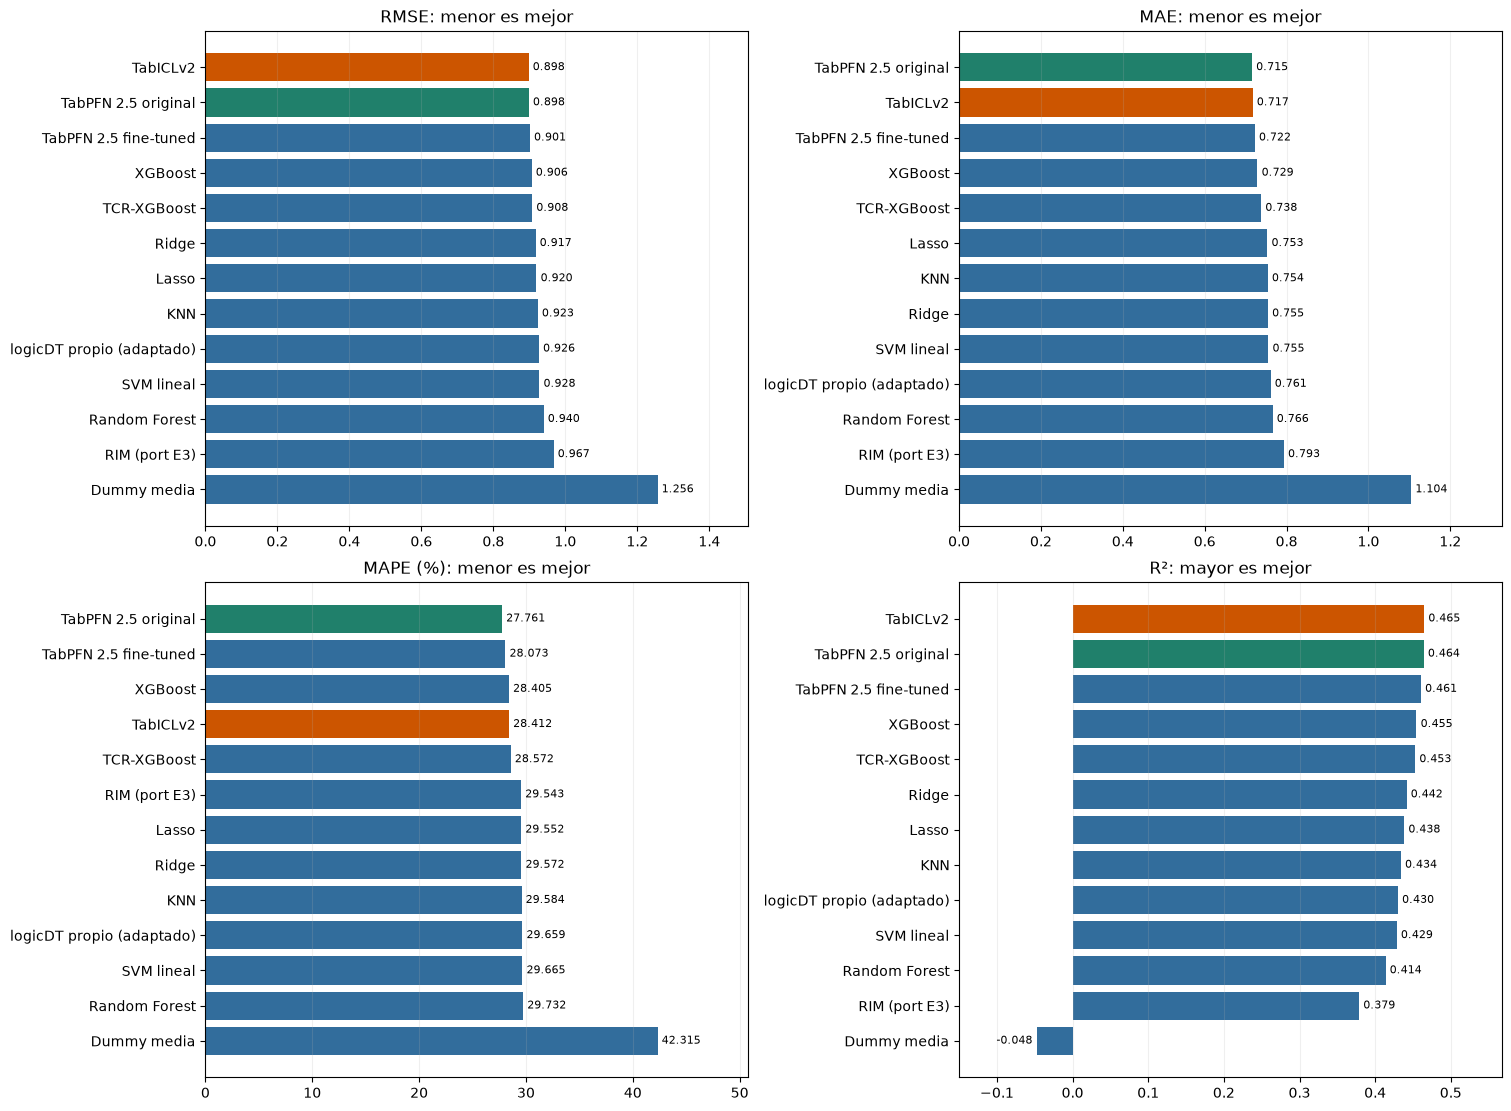

,modelo,metrica,diferencia_ajustado_menos_referencia,IC_2.5%,IC_97.5%,p_bilateral,p_Holm_familia_conocida
0,KNN,RMSE,-0.004436,-0.044821,0.036077,0.82690,1.00000
1,Ridge,RMSE,-0.010615,-0.032070,0.005268,0.31128,1.00000
2,Lasso,RMSE,-0.008056,-0.020001,0.001928,0.15770,1.00000
3,Random Forest,RMSE,0.011930,-0.024657,0.048603,0.51846,1.00000
4,XGBoost,RMSE,-0.021432,-0.054703,0.012122,0.21102,1.00000
5,logicDT,RMSE,-0.001268,-0.036852,0.030833,0.94434,1.00000
6,TabPFN ajustado,RMSE,-0.026336,-0.056160,0.002756,0.08018,0.72162
7,RIM,RMSE,0.039507,-0.013963,0.095171,0.16266,1.00000
8,TabPFN original,RMSE,-0.029428,-0.061618,0.002094,0.06888,0.68880
9,TCR-XGBoost,RMSE,-0.020010,-0.053416,0.013774,0.24432,1.00000


In [2]:
from evaluar_tabpfn25_finetuned_e3 import show
show(report)
display(pd.DataFrame(report['family_vs_svm']).round(6))

## Contrastes estadísticos

Permutación bilateral pareada por estudiante99999 y bootstrap pareado10000,
semilla42. Diferencia=método actual menos referencia: negativa favorece al actual
para RMSE y positiva para R². El p-valor de ambas métricas coincide porque son el
mismo contraste sobre SSE en el mismo test, no dos evidencias independientes.

Se aplica Holm a los dos pares actuales (SVM y TabPFN original) y se muestra además
Holm para la familia acumulada de candidatos conocidos frente al SVM. Los IC son
marginales, sin ajuste simultáneo. No basta que p sea pequeño: debe comprobarse
la dirección de la diferencia. La inferencia sigue siendo exploratoria por uso
repetido de202530 y es condicional a estos modelos; no incluye variabilidad de
reentrenamiento ni demuestra equivalencia si no se rechaza H0.

In [3]:
for comp in report['paired_comparisons']:
    row=comp['rows'][0]
    print(comp['referencia'],'deltaRMSE=',round(row['diferencia_ajustado_menos_referencia'],6),
          'p=',row['p_bilateral'],'p Holm=',row['p_Holm_dos_pares'])
print('Familia conocida:',len(report['family_vs_svm']),'candidatos vs SVM')
print('Resultados:',report['outputs'])
print('Modelo guardado localmente:',report['private_model'])

SVM lineal deltaRMSE= -0.029891 p= 0.02624 p Holm= 0.05248
TabPFN original deltaRMSE= -0.000463 p= 0.96184 p Holm= 0.96184
Familia conocida: 11 candidatos vs SVM
Resultados: C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\resultados\e3\tabicl_v2
Modelo guardado localmente: C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\modelos_preentrenados\tabicl_v2\modelo_final.joblib


## Reproducibilidad

Hashes de fuente, protocolo, módulos, versiones y referencias en reporte.json y
protocolo.json. Predicciones OOF/test sin IDs, grillas internas cuando corresponda,
auditoría y comparaciones CSV. Los estimadores/contextos se guardan únicamente en
modelos_preentrenados/, ignorado en Git. Usar el venv compartido y las versiones
de requirements_seleccionados_e3.txt; no se crea otro entorno.